# GruBI Programming Exercise 4 - Sequence Alignment

This notebook visualizes the score matrices generated by the `prepare_matrix` functions of the alignment module. It also traces and visualizes the correct path dynamically for both Needleman-Wunsch and Smith-Waterman algorithms using built-in matplotlib functionality.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import exercise_4_8819989 as aligner

def plot_alignment_matrix(score, traceback, seq1, seq2, title, local=False):
    """Plots a score matrix heatmap and overlays the traceback path line."""
    score_arr = np.array(score)
    rows, cols = score_arr.shape
    
    fig, ax = plt.subplots(figsize=(cols * 0.4, rows * 0.4))
    cax = ax.matshow(score_arr, cmap='viridis')
    fig.colorbar(cax, fraction=0.046, pad=0.04)
    
    # Set sequence labels as tick markers
    ax.set_xticks(np.arange(cols))
    ax.set_yticks(np.arange(rows))
    ax.set_xticklabels(['-'] + list(seq2))
    ax.set_yticklabels(['-'] + list(seq1))
    ax.tick_params(top=True, bottom=False, labeltop=True, labelbottom=False)
    
    # Add text for the cell scores
    threshold = score_arr.max() / 2.
    for i in range(rows):
        for j in range(cols):
            color = 'white' if score_arr[i, j] < threshold else 'black'
            ax.text(j, i, str(score_arr[i, j]), va='center', ha='center', 
                    color=color, fontsize=8)
            
    # Track back extraction loop
    path_x, path_y = [], []
    
    if not local:
        i, j = rows - 1, cols - 1  # Bottom right for global
        while i > 0 or j > 0:
            path_x.append(j)
            path_y.append(i)
            if traceback[i][j] == 'D':
                i, j = i - 1, j - 1
            elif traceback[i][j] == 'U':
                i -= 1
            elif traceback[i][j] == 'L':
                j -= 1
            else:
                break
        path_x.append(j)
        path_y.append(i) # Final point
    else:
        # Find matrix max coordinate to trace back for local alignment
        max_idx = np.unravel_index(np.argmax(score_arr), score_arr.shape)
        i, j = max_idx
        while traceback[i][j] != '*' and score_arr[i][j] > 0:
            path_x.append(j)
            path_y.append(i)
            if traceback[i][j] == 'D':
                i, j = i - 1, j - 1
            elif traceback[i][j] == 'U':
                i -= 1
            elif traceback[i][j] == 'L':
                j -= 1
            else:
                break
        path_x.append(j)
        path_y.append(i) # Final zero point
        
    # Plot backtracking visual representation line
    ax.plot(path_x, path_y, color='red', linewidth=2, marker='o', markersize=4)
    
    plt.title(title, pad=20, fontsize=14, fontweight='bold')
    plt.show()


### Provide User Testing Parameters
Adjust strings and penalities easily by adapting the default parameters.

In [2]:
seq1 = "GGCAATTACACCTAGATT"
seq2 = "GGCTTACACTTGATTTTTTT"
scoring_function = {'match': 6, 'mismatch': -2, 'gap': -5}


### Visualize Global Alignment (Needleman-Wunsch)

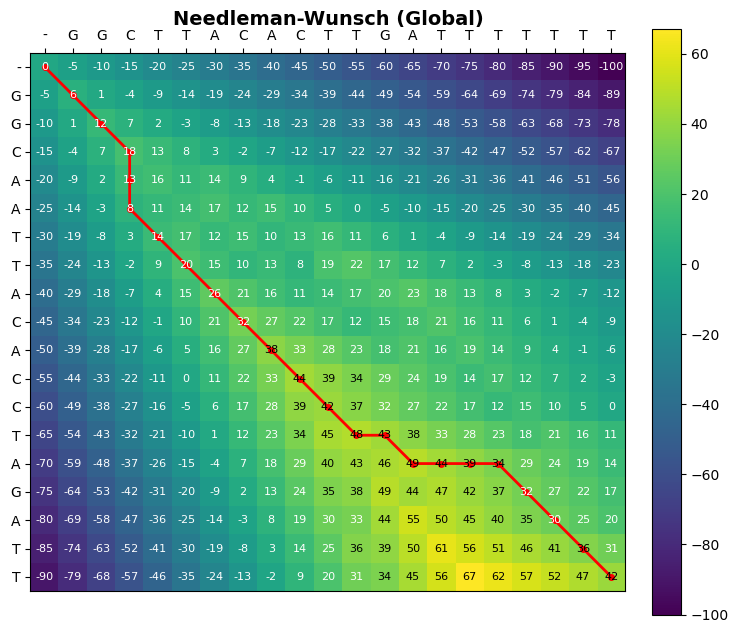

In [3]:
score_nw, trace_nw = aligner.prepare_matrix_needleman_wish(scoring_function, seq1, seq2)
plot_alignment_matrix(score_nw, trace_nw, seq1, seq2, "Needleman-Wunsch (Global)", local=False)


### Visualize Local Alignment (Smith-Waterman)

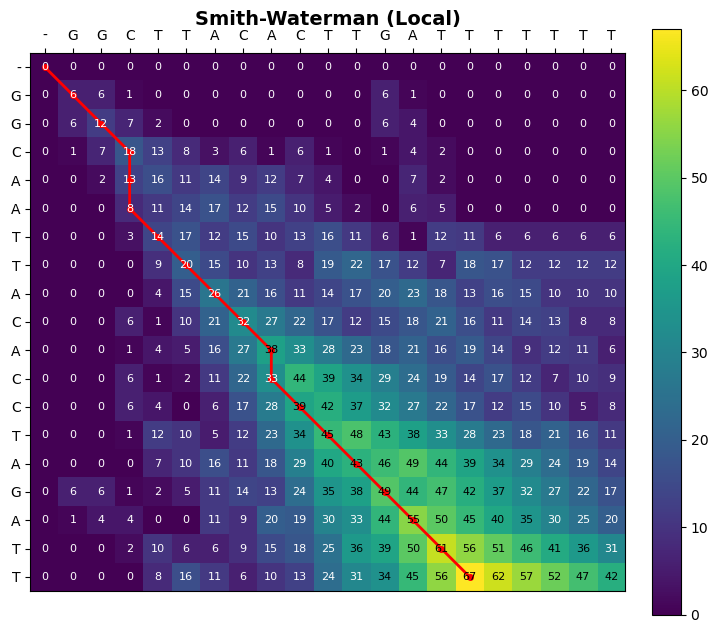

In [4]:
score_sw, trace_sw = aligner.prepare_matrix_smith_waterman(scoring_function, seq1, seq2)
plot_alignment_matrix(score_sw, trace_sw, seq1, seq2, "Smith-Waterman (Local)", local=True)
